# 02 · Live Vessel Noise Modeling & 11-Model Benchmark

End-to-end training and comparison on source-disjoint `train` / `val` / unseen-station `holdout`, benchmarking Notebook 01 baselines (`Constant_Mean`, `Physics_q15`, `V1_RF_MaxShift`) against upgraded 2s deci-decade V2 models (`RF_v2`, `Linear`, `HistGBM`, `LightGBM`, `XGBoost`, `CatBoost`, `PyTorch CNN2D`, `Ensemble_v2`).


In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("PYTHONHASHSEED", "42")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

# Import torch before GBDT C extensions to prevent macOS OpenMP conflicts.
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve, root_mean_squared_error

warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").is_dir():
    ROOT = ROOT.parent
if str(ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(ROOT / "scripts"))

from build_synthetic_mixtures_v1 import BANDS
from extract_external_decidecade import EXACT_CENTRES
from modeling_v2_features import (
    build_cnn_tensors,
    compute_physics_baseline_share,
    extract_features,
    extract_v1_combined96_features,
)
from modeling_v2_train import (
    ALL_BENCHMARK_MODELS,
    _select_torch_device,
    compute_metrics,
    eval_constant_mean,
    eval_physics_q15,
    fit_ensemble_and_export,
    seed_everything,
    train_cv_catboost,
    train_cv_cnn2d,
    train_cv_histgbm,
    train_cv_lightgbm,
    train_cv_linear,
    train_cv_random_forest,
    train_cv_xgboost,
)

plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.25})
DATA_PROC = ROOT / "data/processed"
SYN_DIR = ROOT / "data/synthetic/modeling_v2"
REP_DIR = ROOT / "reports/modeling_v2"
MOD_DIR = ROOT / "models/v2"
SUB_PATH = ROOT / "submissions/candidate_v2_ensemble.csv"

seed_everything(42, torch_threads=4)
_ = _select_torch_device("cpu")
print("Deterministic mode: CPU (torch_threads=4, deterministic_algorithms=True)")


Deterministic mode: CPU (torch_threads=4, deterministic_algorithms=True)


## 1. External Vessel & Background Spectral Profiles

VTUAD (`525` clips) and HearMyShip (`96` clips) share identical 2s Hann deci-decade extraction matching the competition's `minute_band_power`.


,Dataset,Units,Categories,Splits
0,VTUAD 2s (v1.3.0),"2,511 mins / 525 clips",11,"{'background_reference': 38, 'train': 410, 'va..."
1,HearMyShip 2s,96 clips (975 x 2s segs),8,"{'train': 75, 'validation': 21}"
2,SA Background Manifest,"88,143 x 15-min windows",8,"{'train': 67463, 'validation': 16946, 'exclude..."


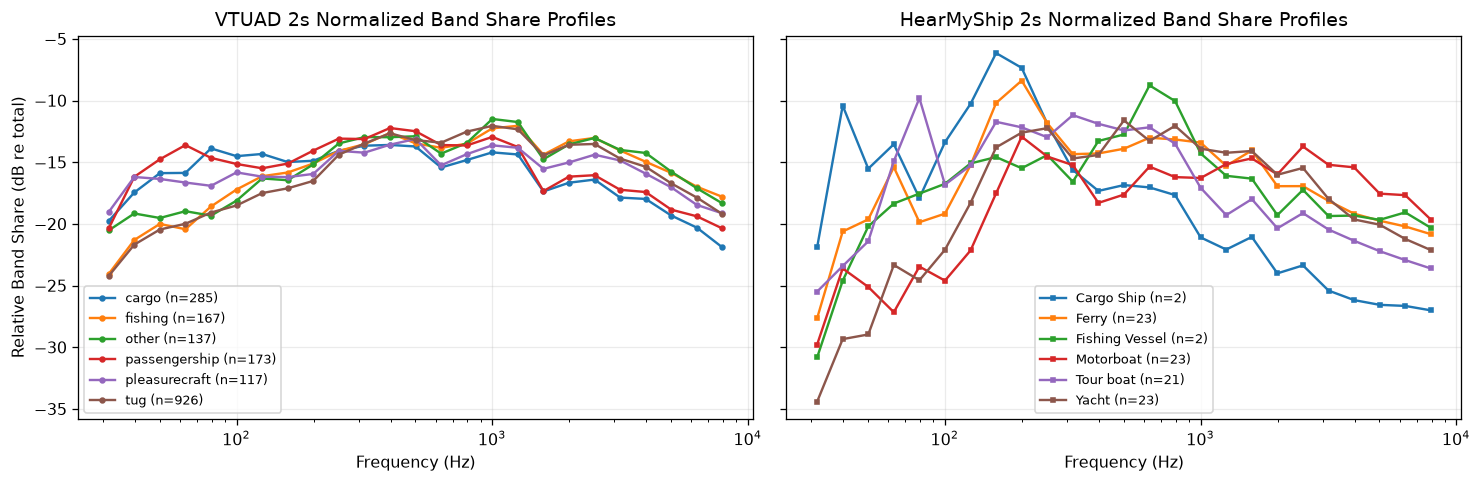

In [2]:
vtuad_df = pd.read_parquet(DATA_PROC / "vtuad_decidecade_2s_minutes.parquet")
hms_df = pd.read_parquet(DATA_PROC / "hearmyship_decidecade_2s_clips.parquet")
bg_manifest = pd.read_csv(ROOT / "reports/eda/background_split_manifest_v2.csv")

inv = pd.DataFrame([
    {
        "Dataset": "VTUAD 2s (v1.3.0)",
        "Units": f"{len(vtuad_df):,} mins / {vtuad_df['clip_uid'].nunique()} clips",
        "Categories": vtuad_df.loc[vtuad_df["label"] != "background", "label"].nunique(),
        "Splits": dict(vtuad_df.groupby("source_split")["clip_uid"].nunique()),
    },
    {
        "Dataset": "HearMyShip 2s",
        "Units": f"{len(hms_df)} clips ({hms_df['n_segments'].sum():,} x 2s segs)",
        "Categories": hms_df["category"].nunique(),
        "Splits": dict(hms_df["source_split"].value_counts()),
    },
    {
        "Dataset": "SA Background Manifest",
        "Units": f"{len(bg_manifest):,} x 15-min windows",
        "Categories": bg_manifest["station"].nunique(),
        "Splits": dict(bg_manifest["split"].value_counts()),
    },
])
display(inv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
vt_act = vtuad_df[vtuad_df["label"] != "background"]
for cls in sorted(vt_act["label"].value_counts().head(6).index):
    sub = vt_act[vt_act["label"] == cls][BANDS].to_numpy()
    rel_db = 10.0 * np.log10(np.maximum(sub / np.maximum(sub.sum(axis=1, keepdims=True), 1e-30), 1e-12))
    axes[0].semilogx(EXACT_CENTRES, np.median(rel_db, axis=0), marker="o", ms=3, label=f"{cls} (n={len(sub)})")
axes[0].set_title("VTUAD 2s Normalized Band Share Profiles")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Relative Band Share (dB re total)")
axes[0].legend(fontsize=8)

for cat in sorted(hms_df["category"].value_counts().head(6).index):
    sub = hms_df[hms_df["category"] == cat][BANDS].to_numpy()
    rel_db = 10.0 * np.log10(np.maximum(sub / np.maximum(sub.sum(axis=1, keepdims=True), 1e-30), 1e-12))
    axes[1].semilogx(EXACT_CENTRES, np.median(rel_db, axis=0), marker="s", ms=3, label=f"{cat} (n={len(sub)})")
axes[1].set_title("HearMyShip 2s Normalized Band Share Profiles")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 2. Leak-Free Simulator & Spectrogram Verification

Background runs and vessel hulls/groups are disjoint across 5 `train` CV folds, `val`, and unseen-station `holdout` (`09_Fish_Hoek`, `10_Sea_Point`).


,Split,Rows,Zero Share,Mean Share,Mean Obs Min,Stations
0,train,6000,0.2262,0.2713,14.49,6
1,val,1500,0.2320,0.2715,14.49,6
2,holdout,541,0.1996,0.2803,14.44,2


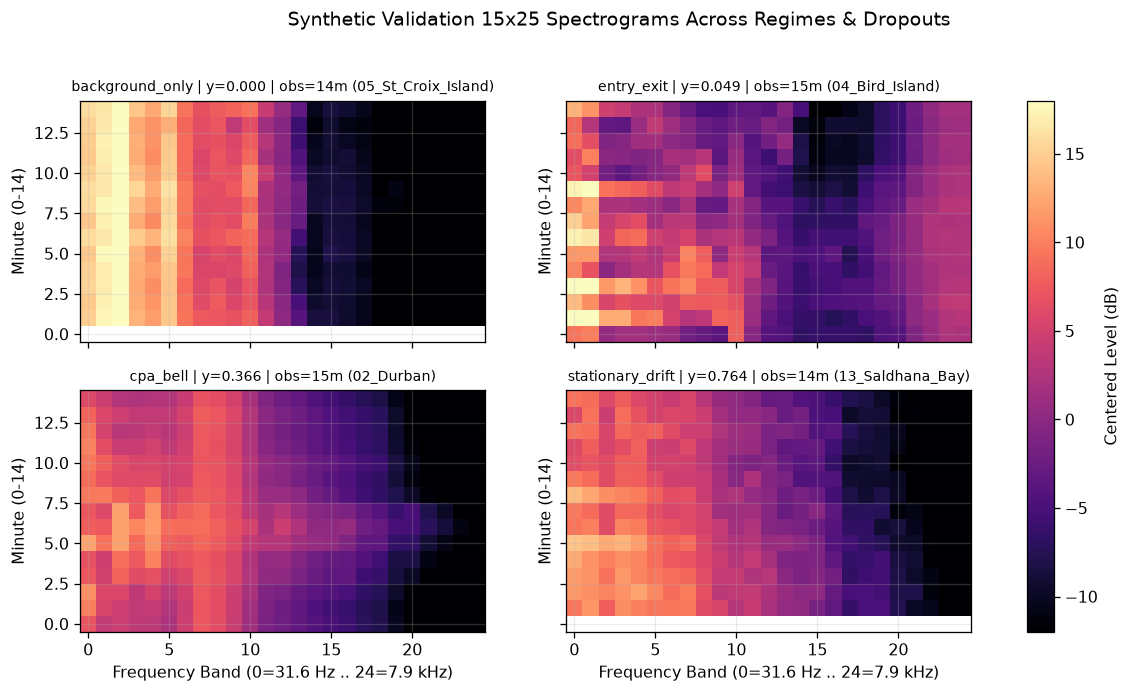

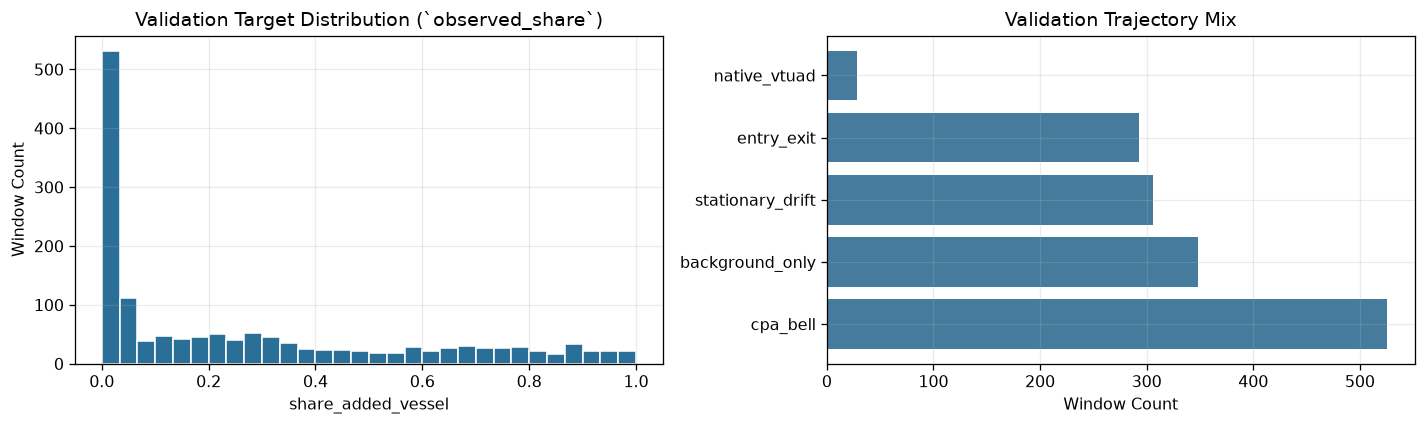

In [3]:
manifest = json.loads((SYN_DIR / "manifest.json").read_text())
split_summary = pd.DataFrame([
    {
        "Split": k,
        "Rows": v["rows"],
        "Zero Share": round(v["zero_fraction"], 4),
        "Mean Share": round(v["mean_share"], 4),
        "Mean Obs Min": round(v["mean_obs_minutes"], 2),
        "Stations": len(v["stations"]),
    }
    for k, v in manifest.items()
])
display(split_summary)

tr_npz = np.load(SYN_DIR / "train.npz")
va_npz = np.load(SYN_DIR / "val.npz")
ho_npz = np.load(SYN_DIR / "holdout.npz")

X_tr, y_tr, folds_tr = tr_npz["X"], tr_npz["y"].astype(np.float64), tr_npz["fold"]
X_va, y_va = va_npz["X"], va_npz["y"].astype(np.float64)
X_ho, y_ho = ho_npz["X"], ho_npz["y"].astype(np.float64)
y_pos_tr = (y_tr > 0.0).astype(np.int64)

va_prov = pd.read_csv(SYN_DIR / "val_provenance.csv")
sample_idxs = [
    int(va_prov.index[va_prov["observed_share"] == 0.0][0]),
    int(va_prov.index[(va_prov["observed_share"] > 0.03) & (va_prov["observed_share"] < 0.12)][0]),
    int(va_prov.index[(va_prov["observed_share"] > 0.30) & (va_prov["observed_share"] < 0.55) & (va_prov["trajectory_mode"] == "cpa_bell")][0]),
    int(va_prov.index[va_prov["observed_share"] > 0.70][0]),
]

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.0), sharex=True, sharey=True)
for ax, idx in zip(axes.ravel(), sample_idxs):
    mat = X_va[idx] - np.nanmedian(X_va[idx])
    im = ax.imshow(mat, aspect="auto", origin="lower", cmap="magma", vmin=-12, vmax=18)
    row = va_prov.iloc[idx]
    ax.set_title(f"{row['trajectory_mode']} | y={row['observed_share']:.3f} | obs={row['n_obs_minutes']}m ({row['station']})", fontsize=9)
    ax.set_ylabel("Minute (0-14)")
axes[1, 0].set_xlabel("Frequency Band (0=31.6 Hz .. 24=7.9 kHz)")
axes[1, 1].set_xlabel("Frequency Band (0=31.6 Hz .. 24=7.9 kHz)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Centered Level (dB)")
plt.suptitle("Synthetic Validation 15x25 Spectrograms Across Regimes & Dropouts", y=1.01)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].hist(y_va, bins=30, color="#2a6f97", edgecolor="white")
axes[0].set_title("Validation Target Distribution (`observed_share`)")
axes[0].set_xlabel("share_added_vessel")
axes[0].set_ylabel("Window Count")
mode_counts = va_prov["trajectory_mode"].value_counts()
axes[1].barh(mode_counts.index, mode_counts.values, color="#457b9d")
axes[1].set_title("Validation Trajectory Mix")
axes[1].set_xlabel("Window Count")
plt.tight_layout()
plt.show()


## 3. Feature Extraction & `+37.5 dB` Offset-Invariance Verification

I extract both Notebook 01 legacy features (`F_v1`: 96 dims with max-shift & interpolation) and upgraded V2 features (`F_v2`: 138 mask-aware features + `(N, 4, 15, 25)` CNN tensors).


In [4]:
F_v1_tr = extract_v1_combined96_features(X_tr)
F_v1_va = extract_v1_combined96_features(X_va)
F_v1_ho = extract_v1_combined96_features(X_ho)

F_tr_df = extract_features(X_tr)
F_va_df = extract_features(X_va)
F_ho_df = extract_features(X_ho)
feat_names = list(F_tr_df.columns)
F_tr, F_va, F_ho = F_tr_df.to_numpy(dtype=np.float64), F_va_df.to_numpy(dtype=np.float64), F_ho_df.to_numpy(dtype=np.float64)

T_tr, T_va, T_ho = build_cnn_tensors(X_tr), build_cnn_tensors(X_va), build_cnn_tensors(X_ho)

sub_x = X_va[:40]
inv_df = pd.DataFrame([
    {"Component": "V2 Tabular Features (138 dims)", "Max |f(X+37.5) - f(X)|": float(np.max(np.abs(extract_features(sub_x).to_numpy() - extract_features(sub_x + 37.5).to_numpy())))},
    {"Component": "CNN2D 4-Channel Tensor", "Max |f(X+37.5) - f(X)|": float(np.max(np.abs(build_cnn_tensors(sub_x) - build_cnn_tensors(sub_x + 37.5))))},
    {"Component": "V1 Legacy 96 Features", "Max |f(X+37.5) - f(X)|": float(np.max(np.abs(extract_v1_combined96_features(sub_x) - extract_v1_combined96_features(sub_x + 37.5))))},
    {"Component": "Physics_q15 Share", "Max |f(X+37.5) - f(X)|": float(np.max(np.abs(compute_physics_baseline_share(sub_x)[0] - compute_physics_baseline_share(sub_x + 37.5)[0])))},
])
display(inv_df)
print(f"Shapes -> F_v1: {F_v1_tr.shape}, F_v2: {F_tr.shape}, T_cnn: {T_tr.shape}")


,Component,Max |f(X+37.5) - f(X)|
0,V2 Tabular Features (138 dims),3.329248e+00
1,CNN2D 4-Channel Tensor,1.072884e-06
2,V1 Legacy 96 Features,1.144409e-05
3,Physics_q15 Share,4.831001e-07


Shapes -> F_v1: (6000, 96), F_v2: (6000, 138), T_cnn: (6000, 4, 15, 25)


## 4. Live 5-Fold Model Runs (Baselines, Individual Families & Ensemble)

Each family fits strictly on `train` CV folds and reports validation (`val`) and unseen-station (`holdout`) metrics plus runtime.


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,Constant_Mean,0.00,0.6953,0.5000,0.7007,0.5000
1,Physics_q15,4.77,0.5282,0.5326,0.6174,0.5766


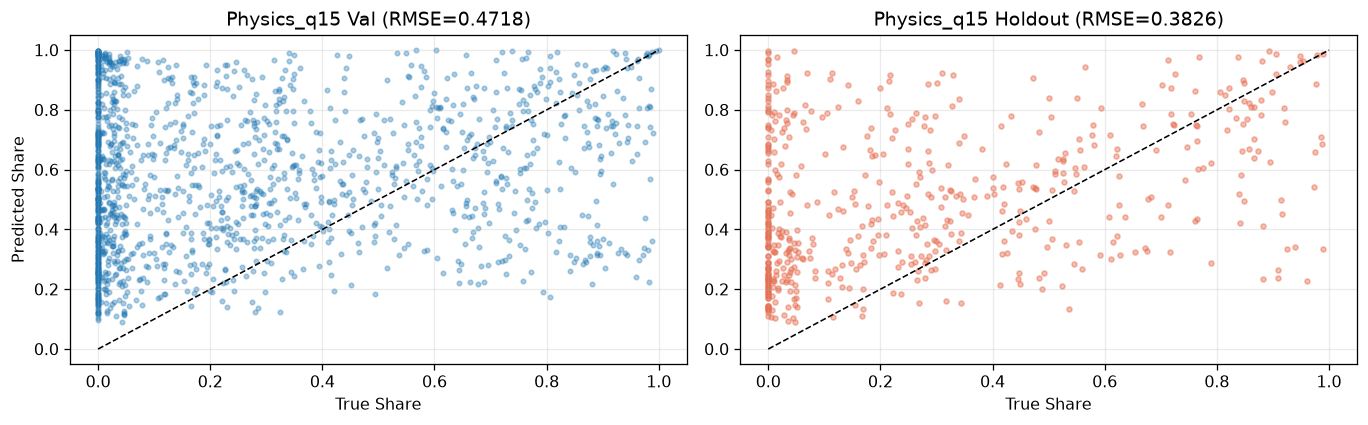

In [5]:
# 4.1 Non-GBDT Anchors: Constant_Mean & Physics_q15
results = {}

def report_live(res: dict) -> pd.DataFrame:
    results[res["name"]] = res
    row_va = compute_metrics("val", res["name"], y_va, res["val_share"], res["val_score"])
    row_ho = compute_metrics("holdout", res["name"], y_ho, res["ho_share"], res["ho_score"])
    return pd.DataFrame([
        {
            "Model": res["name"],
            "Time (s)": round(res["elapsed_s"], 2),
            "Val 1-RMSE": round(row_va["zindi_score_1_minus_rmse"], 4),
            "Val AUC": round(row_va["roc_auc"], 4),
            "Holdout 1-RMSE": round(row_ho["zindi_score_1_minus_rmse"], 4),
            "Holdout AUC": round(row_ho["roc_auc"], 4),
        }
    ])

display(pd.concat([
    report_live(eval_constant_mean(y_tr, y_va, y_ho, folds_tr)),
    report_live(eval_physics_q15(X_tr, X_va, X_ho)),
], ignore_index=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(y_va, results["Physics_q15"]["val_share"], s=8, alpha=0.35)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title(f"Physics_q15 Val (RMSE={root_mean_squared_error(y_va, results['Physics_q15']['val_share']):.4f})")
axes[0].set_xlabel("True Share"); axes[0].set_ylabel("Predicted Share")

axes[1].scatter(y_ho, results["Physics_q15"]["ho_share"], s=10, alpha=0.45, color="#e76f51")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title(f"Physics_q15 Holdout (RMSE={root_mean_squared_error(y_ho, results['Physics_q15']['ho_share']):.4f})")
axes[1].set_xlabel("True Share")
plt.tight_layout()
plt.show()


In [6]:
# 4.2 Notebook 01 Legacy RandomForest (`V1_RF_MaxShift`) vs V2 Features (`RF_v2`)
display(pd.concat([
    report_live(train_cv_random_forest("V1_RF_MaxShift", F_v1_tr, y_tr, y_pos_tr, F_v1_va, F_v1_ho, folds_tr, seed=24)),
    report_live(train_cv_random_forest("RF_v2", F_tr, y_tr, y_pos_tr, F_va, F_ho, folds_tr, seed=42)),
], ignore_index=True))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,V1_RF_MaxShift,17.60,0.8270,0.9578,0.8390,0.8980
1,RF_v2,19.81,0.8444,0.9545,0.8556,0.9095


In [7]:
# 4.3 Regularized Linear (`Ridge` + `LogisticRegression`)
display(report_live(train_cv_linear(F_tr, y_tr, y_pos_tr, F_va, F_ho, folds_tr)))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,Linear,0.17,0.8245,0.9406,0.8321,0.9194


In [8]:
# 4.4 Scikit-learn HistGradientBoosting (`HistGBM`)
display(report_live(train_cv_histgbm(F_tr, y_tr, y_pos_tr, F_va, F_ho, folds_tr)))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,HistGBM,15.1,0.86,0.9605,0.8708,0.9031


In [9]:
# 4.5 LightGBM (5-fold with disjoint `(k+1)%5` early stopping)
display(report_live(train_cv_lightgbm(F_tr, y_tr, y_pos_tr, F_va, F_ho, folds_tr, n_jobs=1)))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,LightGBM,30.03,0.8632,0.959,0.8721,0.9091


In [10]:
# 4.6 XGBoost Hist (5-fold with disjoint `(k+1)%5` early stopping)
display(report_live(train_cv_xgboost(F_tr, y_tr, y_pos_tr, F_va, F_ho, folds_tr, n_jobs=1)))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,XGBoost,48.28,0.8619,0.9583,0.8712,0.906


In [11]:
# 4.7 CatBoost (5-fold with disjoint `(k+1)%5` early stopping)
display(report_live(train_cv_catboost(F_tr, y_tr, y_pos_tr, F_va, F_ho, folds_tr, thread_count=4)))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,CatBoost,51.19,0.86,0.9606,0.867,0.9108


In [12]:
# 4.8 PyTorch 2D Spatiotemporal Residual CNN (`AcousticCNN2D`)
display(report_live(train_cv_cnn2d(T_tr, y_tr, y_pos_tr, T_va, T_ho, folds_tr, epochs=24, batch_size=128, device_pref="cpu")))


,Model,Time (s),Val 1-RMSE,Val AUC,Holdout 1-RMSE,Holdout AUC
0,CNN2D,730.46,0.8722,0.9711,0.8835,0.9425


In [13]:
# 4.9 Fit OOF Simplex Meta-Weights (`Ensemble_v2`) & Export Reports / Submission
metrics_df, weights_payload, sanity = fit_ensemble_and_export(
    results, y_tr, y_va, y_ho, feat_names,
    data_dir=SYN_DIR, models_dir=MOD_DIR, reports_dir=REP_DIR, submission_path=SUB_PATH,
)
display(pd.DataFrame({
    "Model": weights_payload["models"],
    "Share Weight": [round(weights_payload["share_weights"][m], 4) for m in weights_payload["models"]],
    "Score Weight": [round(weights_payload["score_weights"][m], 4) for m in weights_payload["models"]],
    "Train+Eval Time (s)": [round(results[m]["elapsed_s"], 2) for m in weights_payload["models"]],
}))


,Model,Share Weight,Score Weight,Train+Eval Time (s)
0,RF_v2,0.0000,0.0000,19.81
1,Linear,0.0000,0.0010,0.17
2,HistGBM,0.1433,0.2916,15.10
3,LightGBM,0.1142,0.0000,30.03
4,XGBoost,0.1108,0.0862,48.28
5,CatBoost,0.1155,0.0000,51.19
6,CNN2D,0.5162,0.6212,730.46


## 5. Master End-of-Notebook Comparison Across All 11 Models

Comparing every model family side-by-side on validation (`val`, `n=1,500`) and completely unseen South African stations (`holdout`, `n=541`).


,Val 1-RMSE,Val RMSE,Val AUC,Holdout 1-RMSE,Holdout RMSE,Holdout AUC,Holdout Gain vs V1_RF,Time (s)
model,,,,,,,,
CNN2D,0.8722,0.1278,0.9711,0.8835,0.1165,0.9425,0.0445,730.4635
Ensemble_v2,0.8747,0.1253,0.9725,0.8833,0.1167,0.9365,0.0443,0.0253
LightGBM,0.8632,0.1368,0.9590,0.8721,0.1279,0.9091,0.0331,30.0297
XGBoost,0.8619,0.1381,0.9583,0.8712,0.1288,0.9060,0.0322,48.2816
HistGBM,0.8600,0.1400,0.9605,0.8708,0.1292,0.9031,0.0318,15.0965
CatBoost,0.8600,0.1400,0.9606,0.8670,0.1330,0.9108,0.0280,51.1924
RF_v2,0.8444,0.1556,0.9545,0.8556,0.1444,0.9095,0.0166,19.8144
V1_RF_MaxShift,0.8270,0.1730,0.9578,0.8390,0.1610,0.8980,0.0000,17.6005
Linear,0.8245,0.1755,0.9406,0.8321,0.1679,0.9194,-0.0070,0.1693


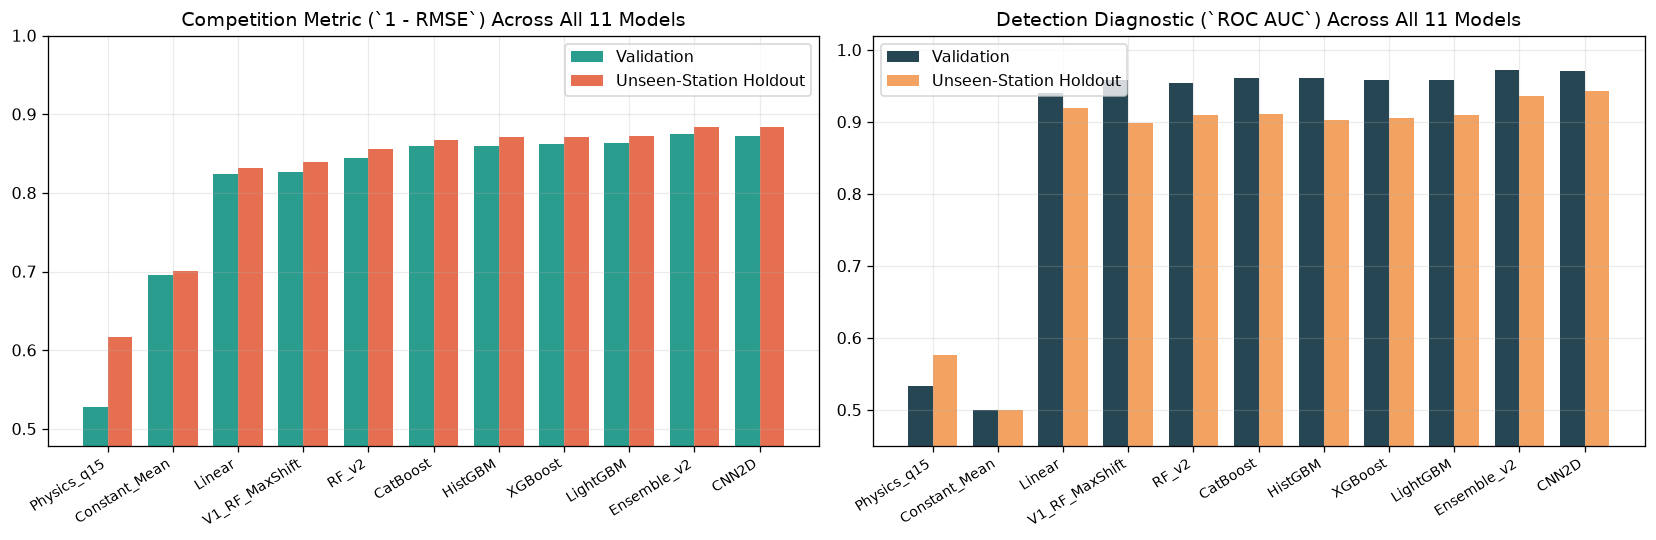

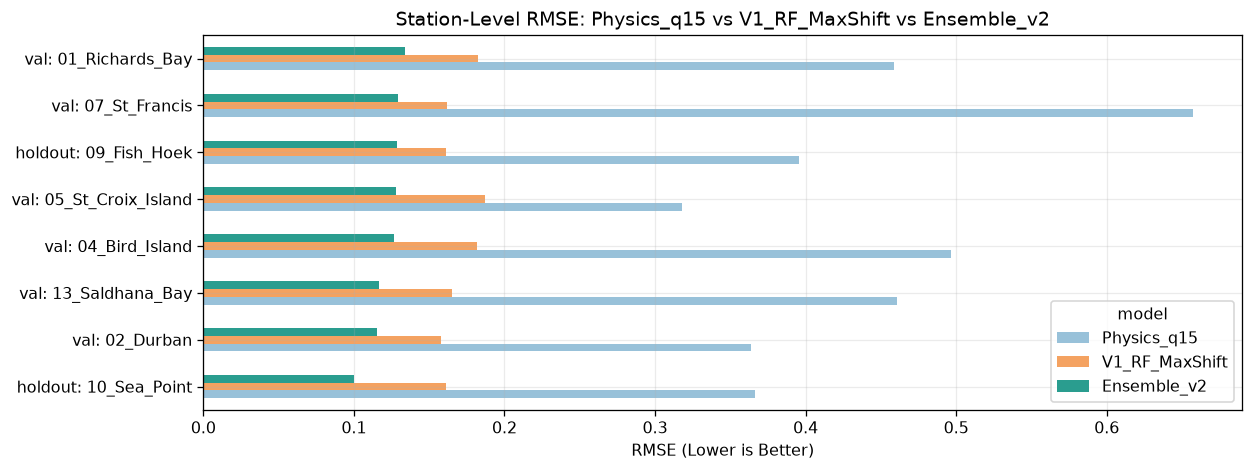

In [14]:
val_tbl = metrics_df[metrics_df["split"] == "val"].set_index("model")
ho_tbl = metrics_df[metrics_df["split"] == "holdout"].set_index("model")

master = pd.DataFrame({
    "Val 1-RMSE": val_tbl["zindi_score_1_minus_rmse"],
    "Val RMSE": val_tbl["rmse"],
    "Val AUC": val_tbl["roc_auc"],
    "Holdout 1-RMSE": ho_tbl["zindi_score_1_minus_rmse"],
    "Holdout RMSE": ho_tbl["rmse"],
    "Holdout AUC": ho_tbl["roc_auc"],
    "Holdout Gain vs V1_RF": ho_tbl["zindi_score_1_minus_rmse"] - float(ho_tbl.loc["V1_RF_MaxShift", "zindi_score_1_minus_rmse"]),
    "Time (s)": [results[m]["elapsed_s"] for m in val_tbl.index],
}).sort_values("Holdout 1-RMSE", ascending=False)
display(master.round(4))

order = master.iloc[::-1].index.tolist()
x = np.arange(len(order))
w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
axes[0].bar(x - w / 2, val_tbl.loc[order, "zindi_score_1_minus_rmse"], width=w, label="Validation", color="#2a9d8f")
axes[0].bar(x + w / 2, ho_tbl.loc[order, "zindi_score_1_minus_rmse"], width=w, label="Unseen-Station Holdout", color="#e76f51")
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=32, ha="right", fontsize=8.5)
axes[0].set_ylim(max(0.0, float(min(val_tbl["zindi_score_1_minus_rmse"].min(), ho_tbl["zindi_score_1_minus_rmse"].min()) - 0.05)), 1.0)
axes[0].set_title("Competition Metric (`1 - RMSE`) Across All 11 Models")
axes[0].legend()

axes[1].bar(x - w / 2, val_tbl.loc[order, "roc_auc"], width=w, label="Validation", color="#264653")
axes[1].bar(x + w / 2, ho_tbl.loc[order, "roc_auc"], width=w, label="Unseen-Station Holdout", color="#f4a261")
axes[1].set_xticks(x); axes[1].set_xticklabels(order, rotation=32, ha="right", fontsize=8.5)
axes[1].set_ylim(0.45, 1.02)
axes[1].set_title("Detection Diagnostic (`ROC AUC`) Across All 11 Models")
axes[1].legend()
plt.tight_layout()
plt.show()

station_df = pd.read_csv(REP_DIR / "station_breakdown.csv")
piv_st = station_df.pivot(index=["split", "station"], columns="model", values="rmse")[["Physics_q15", "V1_RF_MaxShift", "Ensemble_v2"]]
piv_st.index = [f"{sp}: {st}" for sp, st in piv_st.index]
fig, ax = plt.subplots(figsize=(11, 4.2))
piv_st.sort_values("Ensemble_v2").plot(kind="barh", ax=ax, color=["#98c1d9", "#f4a261", "#2a9d8f"])
ax.set_xlabel("RMSE (Lower is Better)")
ax.set_title("Station-Level RMSE: Physics_q15 vs V1_RF_MaxShift vs Ensemble_v2")
plt.tight_layout()
plt.show()


## 6. Error Diagnostics, Feature Importance & Test Submission Sanity

Top physical predictors, trajectory/mask error slices, ROC comparison, and strictly inference-only checks on `submissions/candidate_v2_ensemble.csv`.


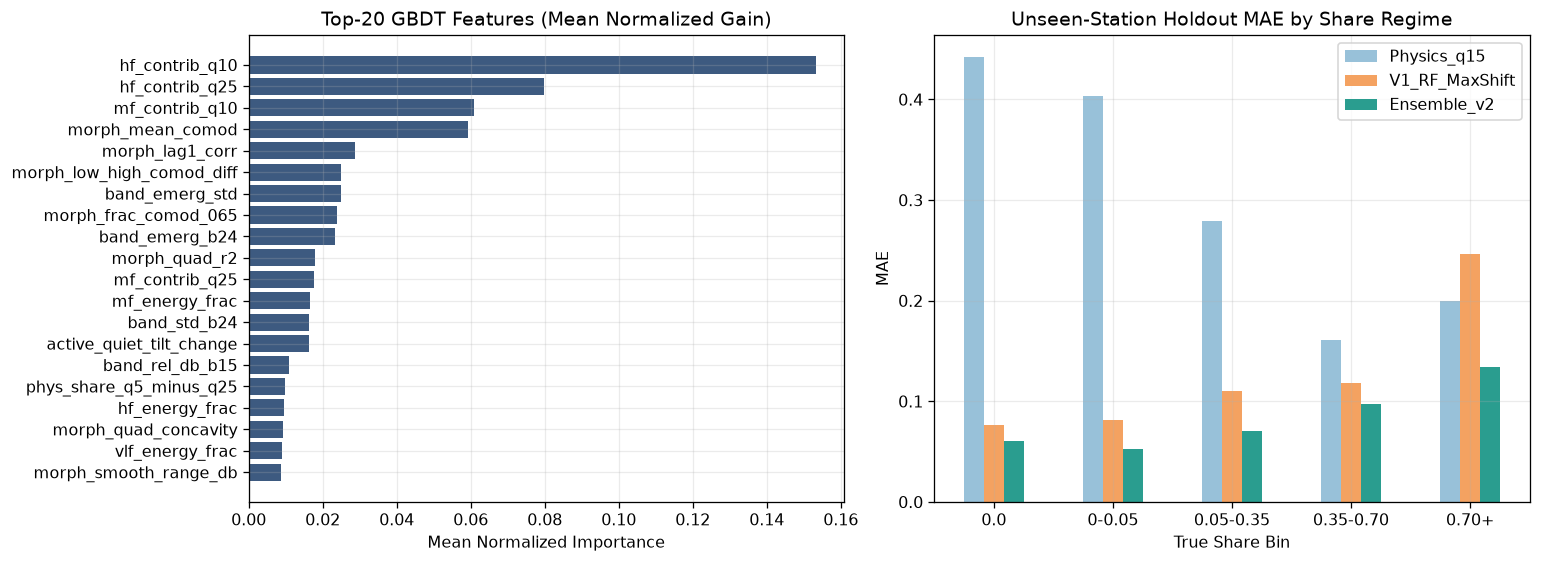

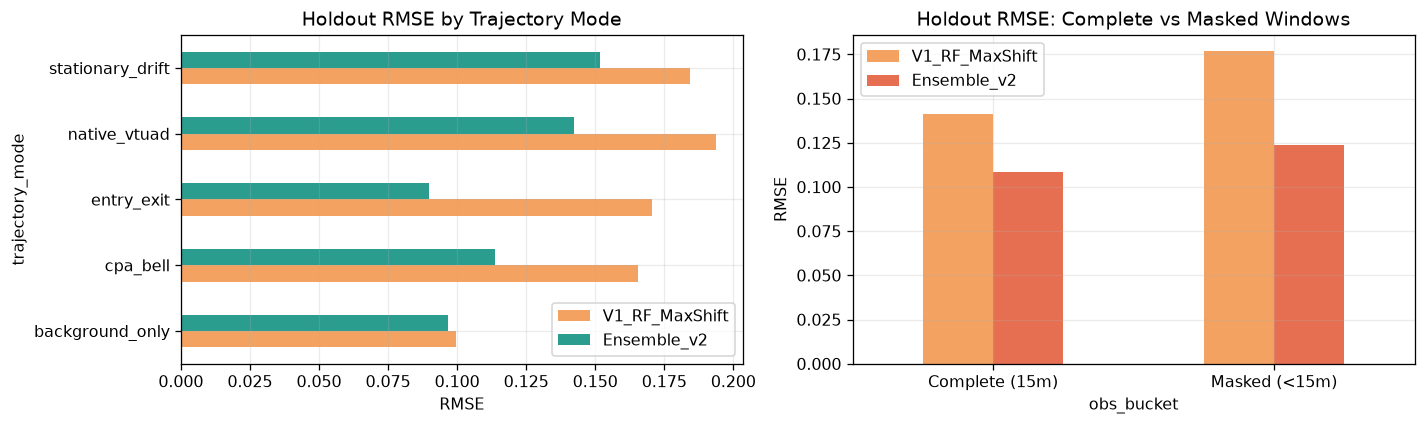

,submission_path,rows,share_mean,share_std,share_q05_q50_q95,score_mean,score_std,score_q05_q50_q95,val_ensemble_score,val_ensemble_auc,holdout_ensemble_score,holdout_ensemble_auc
0,submissions/candidate_v2_ensemble.csv,1500,0.293178,0.217432,"[0.02604, 0.2304, 0.689945]",0.913411,0.150448,"[0.541384, 0.979785, 0.999569]",0.874662,0.972472,0.883327,0.936532


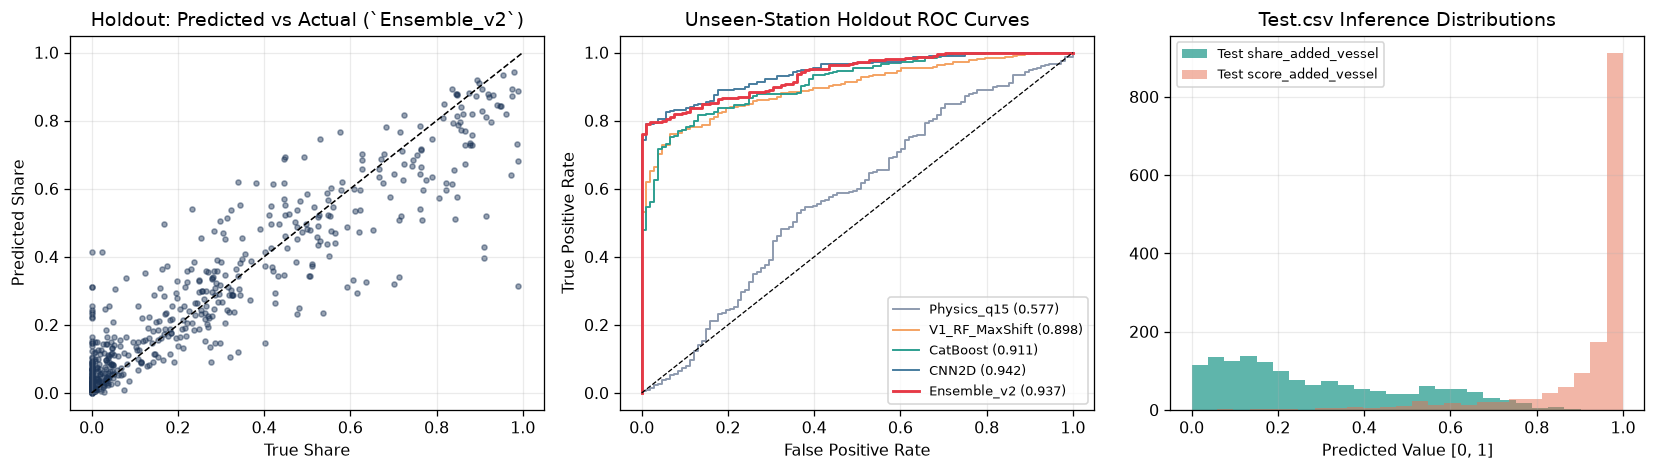

In [15]:
imp_df = pd.read_csv(REP_DIR / "feature_importance.csv").head(20).iloc[::-1]
ho_pred_df = pd.read_parquet(REP_DIR / "holdout_predictions.parquet")

ho_err = ho_pred_df.copy()
ho_err["phys_abs"] = np.abs(ho_err["pred_share_Physics_q15"] - ho_err["y_true"])
ho_err["v1_abs"] = np.abs(ho_err["pred_share_V1_RF_MaxShift"] - ho_err["y_true"])
ho_err["ens_abs"] = np.abs(ho_err["pred_share_Ensemble_v2"] - ho_err["y_true"])
ho_err["share_bin"] = pd.cut(ho_err["y_true"], bins=[-0.001, 0.0, 0.05, 0.35, 0.70, 1.0], labels=["0.0", "0-0.05", "0.05-0.35", "0.35-0.70", "0.70+"])
bin_mae = ho_err.groupby("share_bin", observed=True)[["phys_abs", "v1_abs", "ens_abs"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
axes[0].barh(imp_df["feature"], imp_df["mean_norm_importance"], color="#3d5a80")
axes[0].set_title("Top-20 GBDT Features (Mean Normalized Gain)")
axes[0].set_xlabel("Mean Normalized Importance")

bin_mae.rename(columns={"phys_abs": "Physics_q15", "v1_abs": "V1_RF_MaxShift", "ens_abs": "Ensemble_v2"}).plot(
    kind="bar", ax=axes[1], color=["#98c1d9", "#f4a261", "#2a9d8f"]
)
axes[1].set_title("Unseen-Station Holdout MAE by Share Regime")
axes[1].set_ylabel("MAE"); axes[1].set_xlabel("True Share Bin"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

ho_err["v1_sq"] = (ho_err["pred_share_V1_RF_MaxShift"] - ho_err["y_true"]) ** 2
ho_err["ens_sq"] = (ho_err["pred_share_Ensemble_v2"] - ho_err["y_true"]) ** 2
ho_err["obs_bucket"] = np.where(ho_err["n_obs_minutes"] == 15, "Complete (15m)", "Masked (<15m)")
traj_cmp = ho_err.groupby("trajectory_mode", observed=True)[["v1_sq", "ens_sq"]].mean().pow(0.5)
mask_cmp = ho_err.groupby("obs_bucket", observed=True)[["v1_sq", "ens_sq"]].mean().pow(0.5)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
traj_cmp.rename(columns={"v1_sq": "V1_RF_MaxShift", "ens_sq": "Ensemble_v2"}).plot(kind="barh", ax=axes[0], color=["#f4a261", "#2a9d8f"])
axes[0].set_title("Holdout RMSE by Trajectory Mode"); axes[0].set_xlabel("RMSE")
mask_cmp.rename(columns={"v1_sq": "V1_RF_MaxShift", "ens_sq": "Ensemble_v2"}).plot(kind="bar", ax=axes[1], color=["#f4a261", "#e76f51"])
axes[1].set_title("Holdout RMSE: Complete vs Masked Windows"); axes[1].set_ylabel("RMSE"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

sub_df = pd.read_csv(SUB_PATH)
sample_df = pd.read_csv(ROOT / "data/zindi/raw/sample_submission.csv")
assert len(sub_df) == len(sample_df) == 1500
assert list(sub_df.columns) == list(sample_df.columns)
assert (sub_df["ID"] == sample_df["ID"]).all()
assert np.isfinite(sub_df["share_added_vessel"]).all() and sub_df["share_added_vessel"].between(0, 1).all()
assert np.isfinite(sub_df["score_added_vessel"]).all() and sub_df["score_added_vessel"].between(0, 1).all()
display(pd.DataFrame([sanity]))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
axes[0].scatter(ho_pred_df["y_true"], ho_pred_df["pred_share_Ensemble_v2"], s=10, alpha=0.45, color="#1d3557")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("Holdout: Predicted vs Actual (`Ensemble_v2`)")
axes[0].set_xlabel("True Share"); axes[0].set_ylabel("Predicted Share")

y_bin_ho = (ho_pred_df["y_true"] > 0.0).astype(int)
for m, col in [("Physics_q15", "#8d99ae"), ("V1_RF_MaxShift", "#f4a261"), ("CatBoost", "#2a9d8f"), ("CNN2D", "#457b9d"), ("Ensemble_v2", "#e63946")]:
    fpr, tpr, _ = roc_curve(y_bin_ho, ho_pred_df[f"pred_score_{m}"])
    auc = roc_auc_score(y_bin_ho, ho_pred_df[f"pred_score_{m}"])
    axes[1].plot(fpr, tpr, label=f"{m} ({auc:.3f})", lw=1.8 if m == "Ensemble_v2" else 1.2, color=col)
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_title("Unseen-Station Holdout ROC Curves")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate"); axes[1].legend(fontsize=8)

axes[2].hist(sub_df["share_added_vessel"], bins=25, alpha=0.75, label="Test share_added_vessel", color="#2a9d8f")
axes[2].hist(sub_df["score_added_vessel"], bins=25, alpha=0.50, label="Test score_added_vessel", color="#e76f51")
axes[2].set_title("Test.csv Inference Distributions")
axes[2].set_xlabel("Predicted Value [0, 1]"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 7. Live Leaderboard Feedback & Continuity to Notebook 03

- **Live Zindi Public Result (Submission #2, `submissions/candidate_v2_ensemble.csv`):** Public `1 - RMSE = 0.77501743` (`share RMSE = 0.224982569`), diagnostic `ROC AUC = 0.548377777` (Rank `508`), improving modestly over Submission #1 (`0.761536` / `0.517533`).
- **Diagnosis & Forward Link:** Because `Ensemble_v2` achieved `0.8833` on unseen Fish Hoek + Sea Point synthetic holdout windows yet only `0.5484` AUC publicly, I diagnosed a hydrophone calibration-tilt shortcut (`h(f)`) and unmodeled South African coastal transients. See [`03_domain_generalization_v3_v4_and_standards.ipynb`](03_domain_generalization_v3_v4_and_standards.ipynb) for **Modeling v3**, **Modeling v4**, exact `h(f)` invariance proofs, and my **International Acoustic Standards Benchmark**.
